In [1]:
# laden der Packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy.stats import binom 
from scipy.stats import hypergeom

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [1]:
49*47*46*3*44

13983816

# Erwartungswert von Zufallsvariablen & Diskrete Verteilungen


### Ziele der Übung

- Zufallsvariablen und dessen Erwartungswerte
- Verteilungen pdf und cdf
- Diskrete Verteilungen: Hypergeometrische und Binomial Verteilung

**Hilfestellung:**
- Informationen zur Hypergeometrischen Verteilung in Python: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.hypergeom.html
-  Informationen zur Binomial Verteilung in Python: 
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html

## Aufgabe 1

Auf dem Martinimarkt entdeckst du folgendes Glücksspiel. Für einen Einsatz von 3 Euro kann der Spieler einmal mit zwei Würfel würfeln. Bei der Augensumme 11 und 12 erhält der Spieler jeweils 15 Euro und bei der Augensumme 2 erhält der Spieler 10 Euro. In allen anderen Fällen ist der Einsatz verloren. Macht der Spieler langfristig einen Gewinn?

**Lösung:**

Aus der Aufgabe 2 aus dem vorhergegangenem Notebook wissen wir: 

In [3]:
x = np.arange(2,13)
absH = [1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1] 
relH = np.divide(absH, 36)

dataWürfel = pd.DataFrame(data = {
    "Summe Augenzahl": x,
    "p": relH 
})

dataWürfel

,Summe Augenzahl,p
0,2,0.027778
1,3,0.055556
2,4,0.083333
3,5,0.111111
4,6,0.138889
5,7,0.166667
6,8,0.138889
7,9,0.111111
8,10,0.083333
9,11,0.055556


In [4]:
dataWürfel["Gewinn"] = 0
dataWürfel.loc[dataWürfel["Summe Augenzahl"] == 2, "Gewinn"] = 10
dataWürfel.loc[dataWürfel["Summe Augenzahl"] == 11, "Gewinn"] = 15
dataWürfel.loc[dataWürfel["Summe Augenzahl"] == 12, "Gewinn"] = 15

dataWürfel["netto Gewinn"] = dataWürfel["Gewinn"] - 3

dataWürfel

,Summe Augenzahl,p,Gewinn,netto Gewinn
0,2,0.027778,10,7
1,3,0.055556,0,-3
2,4,0.083333,0,-3
3,5,0.111111,0,-3
4,6,0.138889,0,-3
5,7,0.166667,0,-3
6,8,0.138889,0,-3
7,9,0.111111,0,-3
8,10,0.083333,0,-3
9,11,0.055556,15,12


In [5]:
Erwartungswert = sum(dataWürfel["netto Gewinn"]*dataWürfel["p"])

print('Der Erwartungswert beträgt: {}.'.format(Erwartungswert))

Der Erwartungswert beträgt: -1.4722222222222225.


## Aufgabe 2

Eine Lieferung von 100 Geräten enthält typischerweise fünf defekte. Es werden für die Qualitätskontrolle drei Geräte entnommen.

a) Gib die Wahrscheinlichkeitsverteilung der Zufallsvariablen $X = $ *Anzahl der defekten Geräte in der Stichprobe* an. 

b) Stelle die Wahrscheinlichkeitsverteilung und kumulative Verteilungsfunktion graphisch dar. 

c) Wie groß ist die Wahrscheinlichkeit in dieser Stichprobe 
- kein defektes Gerät,
- höchstens ein defektes Gerät,
- mehr als ein defektes Gerät vorzufinden?

d) Mit wieviel defekten Geräten ist zu rechnen? 

e) Mit wieviel funktionstüchtigen Geräten ist zu rechnen?

**Lösung**

Achtung bei der Hypergeometrischen Verteilung. Die Parameter in der Implementierung sind nicht mit der Theorie ident!

Aus dem Manual: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.hypergeom.html

The hypergeometric distribution models drawing objects from a bin. 
- **M is the total number of objects**, 
- **n is total number of Type I objects** 
- The random variate represents the number of Type I objects in **N drawn without replacement from the total population**.

a) Die Zufallsvariablen $X = $ *Anzahl der defekten Geräte in der Stichprobe* folgt einer hypergeometrischen Verteilung. 

b)

In [6]:
[M, n, N] = [100, 5, 3] 
rv = hypergeom(M, n, N)
x = np.arange(0, n+1)
pdf_geom = rv.pmf(x)
cdf_geom = rv.cdf(x)

In [7]:
print(pdf_geom)
print(cdf_geom)
np.cumsum(pdf_geom)

[8.55998763e-01 1.38064317e-01 5.87507730e-03 6.18429190e-05
 0.00000000e+00 0.00000000e+00]
[0.85599876 0.99406308 0.99993816 1.         1.         1.        ]


array([0.85599876, 0.99406308, 0.99993816, 1.        , 1.        ,
       1.        ])

In [8]:
dataGeräte_geom = pd.DataFrame(data = {'X': x,
                                  'PDF': pdf_geom,
                                  'CDF': cdf_geom})
dataGeräte_geom

,X,PDF,CDF
0,0,0.855999,0.855999
1,1,0.138064,0.994063
2,2,0.005875,0.999938
3,3,0.000062,1.000000
4,4,0.000000,1.000000
5,5,0.000000,1.000000


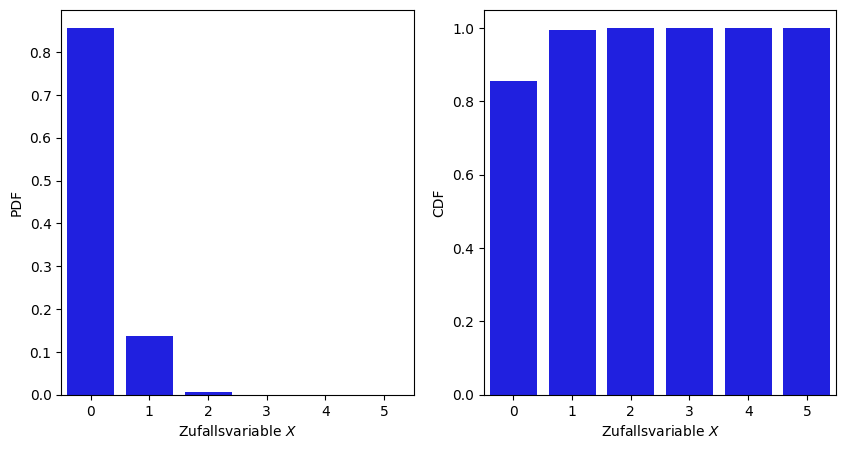

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=dataGeräte_geom, x="X", y="PDF", color="b", ax=axes[0]) # PDF
axes[0].set_xlabel('Zufallsvariable $X$')
axes[0].set_ylabel('PDF')

sns.barplot(data=dataGeräte_geom, x="X", y="CDF", color="b", ax=axes[1]) # CDF
axes[1].set_xlabel('Zufallsvariable $X$')
axes[1].set_ylabel('CDF');

c) Wie groß ist die Wahrscheinlichkeit in dieser Stichprobe 
- kein defektes Gerät,
- höchstens ein defektes Gerät,
- mehr als ein defektes Gerät vorzufinden?

In [10]:
print('P(X = 0) = {:.2f}%.'.format(pdf_geom[0]*100))

P(X = 0) = 85.60%.


$P(X=0) = \frac{\binom{5}{0}\cdot \binom{95}{3}}{\binom{100}{3}} = 85.60\%$

In [11]:
print('P(X <= 1) = {:.2f}%.'.format(cdf_geom[1]*100))

P(X <= 1) = 99.41%.


$P(X \leq 1) = P(X = 0) + P(X = 1) = \frac{\binom{5}{0}\cdot \binom{95}{3}}{\binom{100}{3}} + \frac{\binom{5}{1}\cdot \binom{95}{2}}{\binom{100}{3}}= 99.41\%$

In [12]:
print('P(X > 1) = 1 - P(X <= 1) = {:.2f}%.'.format( (1 - cdf_geom[1])*100))

P(X > 1) = 1 - P(X <= 1) = 0.59%.


$P(X > 1) = 1 - P(X \leq 1) = 1 - ( \frac{\binom{5}{0}\cdot \binom{95}{3}}{\binom{100}{3}} + \frac{\binom{5}{1}\cdot \binom{95}{2}}{\binom{100}{3}} ) = 0.59\%$

d) Mit wieviel defekten Geräten ist zu rechnen? (*Erwartungswert*)

$E(X) = n\cdot \frac{M}{N} = 3\cdot \frac{5}{100} = 0.15$

Es ist kein defektes Gerät zu erwarten. 

In [13]:
3*5/100

0.15

e) Mit wieviel funktionstüchtigen Geräten ist zu rechnen? (Erwartungswert)

$E(X) = n\cdot \frac{M}{N} = 3\cdot \frac{95}{100} = 0.15$

Es sind 3 funktionstüchtige Geräte zu erwarten. 

In [14]:
3*95/100

2.85

## Aufgabe 3

Approximiere die Ergebnisse aus Aufgabe 2 mit der Binomialverteilung. Vergleiche die Ergebnisse. 

Eine Lieferung von 100 Geräten enthält typischerweise fünf defekte. Es werden für die Qualitätskontrolle drei Geräte entnommen.

a) Gib die Wahrscheinlichkeitsverteilung der Zufallsvariablen $X = $ *Anzahl der defekten Geräte in der Stichprobe* an. 

b) Stelle die Wahrscheinlichkeitsverteilung und kumulative Verteilungsfunktion graphisch dar. 

c) Wie groß ist die Wahrscheinlichkeit in dieser Stichprobe 
- kein defektes Gerät,
- höchstens ein defektes Gerät,
- mehr als ein defektes Gerät vorzufinden?

d) Mit wieviel defekten Geräten ist zu rechnen? 

e) Mit wieviel funktionstüchtigen Geräten ist zu rechnen?

f) Vergleiche die Ergebnisse mit den exakten Ergebnissen.

**Lösung**

Die Bedingung für die Gültigkeit der Approximation ist erfüllt, weil $3 \leq 100/20 = 5$

$\Rightarrow n = 3$ und $p = M/N = 5/100 = 0.05$ 

In [15]:
n, p = 3, 5/100

# x = np.arange(0, 6) --> kann von oben übernommen werden
pdf_binom = binom.pmf(x, n, p)
cdf_binom = binom.cdf(x, n, p)

In [16]:
dataGeräte_binom = pd.DataFrame(data = {'X': x,
                                  'PDF': pdf_binom,
                                  'CDF': cdf_binom})
dataGeräte_binom

,X,PDF,CDF
0,0,0.857375,0.857375
1,1,0.135375,0.992750
2,2,0.007125,0.999875
3,3,0.000125,1.000000
4,4,0.000000,1.000000
5,5,0.000000,1.000000


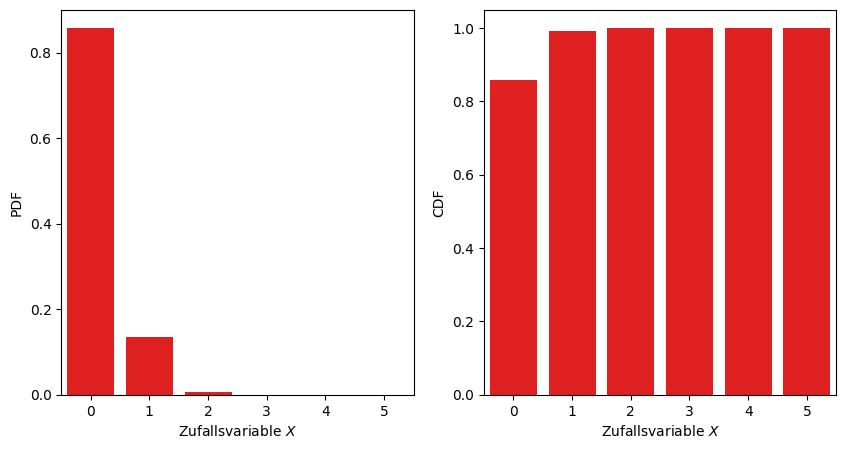

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.barplot(data=dataGeräte_binom, x="X", y="PDF", color="r", ax=axes[0]) # PDF
axes[0].set_xlabel('Zufallsvariable $X$')
axes[0].set_ylabel('PDF')

sns.barplot(data=dataGeräte_binom, x="X", y="CDF", color="r", ax=axes[1]) # CDF
axes[1].set_xlabel('Zufallsvariable $X$')
axes[1].set_ylabel('CDF');

c) Wie groß ist die Wahrscheinlichkeit in dieser Stichprobe 
- kein defektes Gerät,
- höchstens ein defektes Gerät,
- mehr als ein defektes Gerät vorzufinden?

In [18]:
print('P(X = 0) = {:.2f}%.'.format(pdf_binom[0]*100))

P(X = 0) = 85.74%.


$P(X=0) = \binom{3}{0}\cdot (0.05)^{0} \cdot (0.95)^{3} = 85.74\%$

In [19]:
print('P(X <= 1) = {:.2f}%.'.format(cdf_binom[1]*100))

P(X <= 1) = 99.28%.


$P(X=0) = \binom{3}{0}\cdot (0.05)^{0} \cdot (0.95)^{3} + \binom{3}{1}\cdot (0.05)^{1} \cdot (0.95)^{2} = 99.28\%$

In [20]:
print('P(X > 1) = 1 - P(X <= 1) = {:.2f}%.'.format( (1 - cdf_binom[1])*100))

P(X > 1) = 1 - P(X <= 1) = 0.72%.


$P(X> 1) = 1- P(X\leq 1) = 1 - (\binom{3}{0}\cdot (0.05)^{0} \cdot (0.95)^{3} +\binom{3}{1}\cdot (0.05)^{1} \cdot (0.95)^{2}) = 0.72\%$

d) Mit wieviel defekten Geräten ist zu rechnen? (Erwratungswert)

$E(X) = n\cdot p = 3\cdot \frac{5}{100} = 0.15$

Es ist kein defektes Gerät zu erwarten. 

e) Mit wieviel funktionstüchtigen Geräten ist zu rechnen?

$E(X) = n\cdot p = 3\cdot \frac{95}{100} = 2.85$

Es ist kein defektes Gerät zu erwarten. 

f) Vergleiche die Ergebnisse mit den exakten Ergebnissen.

In [21]:
dataGeräte_geom['Verteilung'] = 'geom'
dataGeräte_binom['Verteilung'] = 'binom'

dataVergleich = pd.concat([dataGeräte_geom, dataGeräte_binom], ignore_index=True)

dataVergleich

,X,PDF,CDF,Verteilung
0,0,0.855999,0.855999,geom
1,1,0.138064,0.994063,geom
2,2,0.005875,0.999938,geom
3,3,0.000062,1.000000,geom
4,4,0.000000,1.000000,geom
5,5,0.000000,1.000000,geom
6,0,0.857375,0.857375,binom
7,1,0.135375,0.992750,binom
8,2,0.007125,0.999875,binom
9,3,0.000125,1.000000,binom


<AxesSubplot: xlabel='X', ylabel='PDF'>

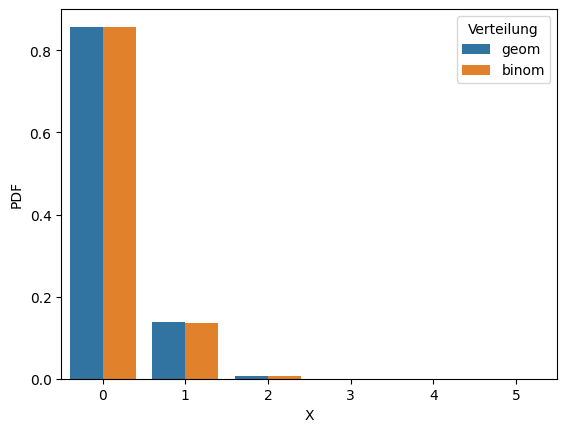

In [22]:
sns.barplot(dataVergleich, x = "X", y = "PDF", hue = "Verteilung")

<AxesSubplot: xlabel='X', ylabel='CDF'>

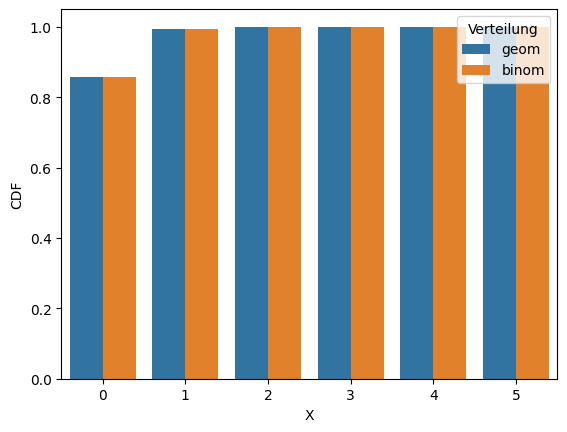

In [23]:
sns.barplot(dataVergleich, x = "X", y = "CDF", hue = "Verteilung")

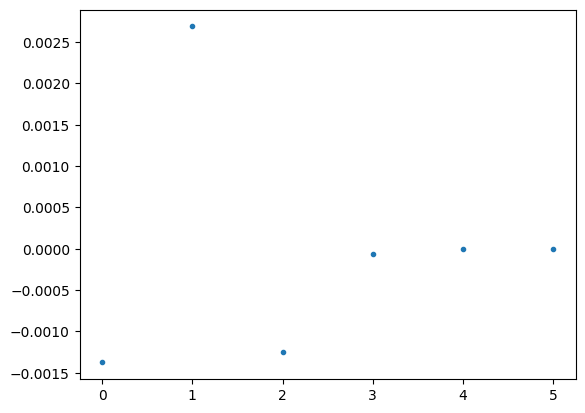

In [24]:
plt.plot(x, pdf_geom - pdf_binom, '.');